# Used Laptop Price Estimator
**BU-CSC 325 Introduction to Machine Learning · Group project**

**Problem.** Used laptops change hands every day, but there's no fair reference price. Sellers guess, buyers can't tell whether an asking price is reasonable, and two laptops with similar specs can sell for very different amounts. We want a tool that serves **both sides of a sale**:

| Side | Question | What our model gives |
|---|---|---|
| **Seller** | What should I ask for this laptop? | an estimate and a fair range, in naira |
| **Buyer** | Is this asking price fair? | the same estimate and range to compare against |
| **Both** | Why that price? | a line-by-line breakdown of how each spec moved the price |

The app asks a few questions a non-expert can answer (brand, year, processor, RAM, storage, a condition checklist, battery life) and prints the answer as an itemised receipt. This notebook covers the machine learning behind it: the data, the cleaning, the features, a comparison of models, the chosen model, and how one prediction becomes the receipt.

Project repository: https://github.com/iamelio/used-laptop-price-estimator. It runs top to bottom in Google Colab in a few minutes.

## 0. Setup

In [1]:
%pip install -q lightgbm "scikit-learn>=1.6"

In [2]:
import subprocess
import sys
from pathlib import Path

REPO = "https://github.com/iamelio/used-laptop-price-estimator.git"
for candidate in (Path("."), Path("..")):
    if (candidate / "model" / "train.py").exists():
        ROOT = candidate.resolve()
        break
else:
    subprocess.run(["git", "clone", "-q", REPO], check=True)
    ROOT = Path("used-laptop-price-estimator").resolve()

sys.path[:0] = [str(ROOT / "model"), str(ROOT / "api")]

In [3]:
import contextlib
import io
import json
import time

import lightgbm
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import sklearn

import train as tr

INK, ORANGE, GREY = "#15171B", "#FF5A1F", "#9AA0A8"
PRICE_TICKS = [5e5, 1e6, 2e6, 4e6, 8e6]
plt.rcParams.update({"figure.figsize": (8, 4), "axes.spines.top": False, "axes.spines.right": False})
millions = plt.FuncFormatter(lambda value, _: f"₦{value / 1e6:.1f}M")


def naira(amount):
    return f"₦{amount:,.0f}"


print("pandas", pd.__version__, "| scikit-learn", sklearn.__version__, "| lightgbm", lightgbm.__version__)

pandas 3.1.1 | scikit-learn 1.9.1 | lightgbm 4.7.0


## 1. The data

| Data | Columns | Source |
|---|---|---|
| **Laptop listings (2,160 rows)** | title, brand, model, CPU, RAM, storage, storage type, GPU, screen, new or refurbished, price in euros | a Spanish online shop, 2023, published on Kaggle and mirrored by the ML Zoomcamp course |
| **Seller answers the data lacks** | condition checklist, battery life | asked in the app, applied as fixed adjustments after the model |

The data comes from a European shop, not the Nigerian used market. That's the project's main limitation, covered in section 15.

## 2. Load and inspect the data *(Week 2)*

In [4]:
raw = pd.read_csv(tr.DATA_URL)

In [5]:
raw.head()

,Laptop,Status,Brand,Model,CPU,RAM,Storage,Storage type,GPU,Screen,Touch,Final Price
0,ASUS ExpertBook B1 B1502CBA-EJ0436X Intel Core...,New,Asus,ExpertBook,Intel Core i5,8,512,SSD,NaN,15.6,No,1009.00
1,Alurin Go Start Intel Celeron N4020/8GB/256GB ...,New,Alurin,Go,Intel Celeron,8,256,SSD,NaN,15.6,No,299.00
2,ASUS ExpertBook B1 B1502CBA-EJ0424X Intel Core...,New,Asus,ExpertBook,Intel Core i3,8,256,SSD,NaN,15.6,No,789.00
3,MSI Katana GF66 12UC-082XES Intel Core i7-1270...,New,MSI,Katana,Intel Core i7,16,1000,SSD,RTX 3050,15.6,No,1199.00
4,HP 15S-FQ5085NS Intel Core i5-1235U/16GB/512GB...,New,HP,15S,Intel Core i5,16,512,SSD,NaN,15.6,No,669.01


In [6]:
raw.tail()

,Laptop,Status,Brand,Model,CPU,RAM,Storage,Storage type,GPU,Screen,Touch,Final Price
2155,Razer Blade 17 FHD 360Hz Intel Core i7-11800H/...,Refurbished,Razer,Blade,Intel Core i7,16,1000,SSD,RTX 3060,17.3,No,2699.99
2156,Razer Blade 17 FHD 360Hz Intel Core i7-11800H/...,Refurbished,Razer,Blade,Intel Core i7,16,1000,SSD,RTX 3070,17.3,No,2899.99
2157,Razer Blade 17 FHD 360Hz Intel Core i7-11800H/...,Refurbished,Razer,Blade,Intel Core i7,32,1000,SSD,RTX 3080,17.3,No,3399.99
2158,Razer Book 13 Intel Evo Core i7-1165G7/16GB/1T...,Refurbished,Razer,Book,Intel Evo Core i7,16,1000,SSD,NaN,13.4,Yes,1899.99
2159,Razer Book FHD+ Intel Evo Core i7-1165G7/16GB/...,Refurbished,Razer,Book,Intel Evo Core i7,16,256,SSD,NaN,13.4,Yes,1699.99


In [7]:
raw.shape

(2160, 12)

In [8]:
raw.dtypes

Laptop              str
Status              str
Brand               str
Model               str
CPU                 str
RAM               int64
Storage           int64
Storage type        str
GPU                 str
Screen          float64
Touch               str
Final Price     float64
dtype: object

In [9]:
raw.describe()

,RAM,Storage,Screen,Final Price
count,2160.000000,2160.000000,2156.000000,2160.000000
mean,15.413889,596.294444,15.168112,1312.638509
std,9.867815,361.220506,1.203329,911.475417
min,4.000000,0.000000,10.100000,201.050000
25%,8.000000,256.000000,14.000000,661.082500
50%,16.000000,512.000000,15.600000,1031.945000
75%,16.000000,1000.000000,15.600000,1708.970000
max,128.000000,4000.000000,18.000000,7150.470000


In [10]:
raw.info()

<class 'pandas.DataFrame'>
RangeIndex: 2160 entries, 0 to 2159
Data columns (total 12 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   Laptop        2160 non-null   str    
 1   Status        2160 non-null   str    
 2   Brand         2160 non-null   str    
 3   Model         2160 non-null   str    
 4   CPU           2160 non-null   str    
 5   RAM           2160 non-null   int64  
 6   Storage       2160 non-null   int64  
 7   Storage type  2118 non-null   str    
 8   GPU           789 non-null    str    
 9   Screen        2156 non-null   float64
 10  Touch         2160 non-null   str    
 11  Final Price   2160 non-null   float64
dtypes: float64(2), int64(2), str(8)
memory usage: 202.6 KB


In [11]:
raw.sample(n=3, random_state=42)

,Laptop,Status,Brand,Model,CPU,RAM,Storage,Storage type,GPU,Screen,Touch,Final Price
2079,MSI Modern 15 A11SBU-620XES Intel Core i7-1165...,Refurbished,MSI,Modern,Intel Core i7,32,1000,SSD,MX 450,15.6,No,1123.29
668,Thomson Neo White Intel Celeron N4020/4GB/64GB...,New,Thomson,Neo,Intel Celeron,4,64,eMMC,NaN,14.1,No,201.05
2073,MSI Modern 14 B11SB-420XES Intel Core i7-1165G...,Refurbished,MSI,Modern,Intel Core i7,32,1000,SSD,MX 450,14.0,No,997.74


## 3. Clean the data *(Week 3)*

In [12]:
raw.isna().sum()

Laptop             0
Status             0
Brand              0
Model              0
CPU                0
RAM                0
Storage            0
Storage type      42
GPU             1371
Screen             4
Touch              0
Final Price        0
dtype: int64

In [13]:
specs = ["Brand", "Model", "CPU", "RAM", "Storage", "Storage type", "GPU", "Screen", "Status"]
print("Exact duplicate rows:", raw.duplicated().sum())
print("Rows that repeat another row's specs:", raw.duplicated(subset=specs).sum())

Exact duplicate rows: 0
Rows that repeat another row's specs: 787


In [14]:
raw["Brand"].value_counts().head(15)

Brand
Asus         415
HP           368
Lenovo       366
MSI          308
Acer         137
Apple        116
Dell          84
Microsoft     77
Gigabyte      48
Razer         37
Medion        32
LG            32
Alurin        29
PcCom         24
Samsung       22
Name: count, dtype: int64

In [15]:
raw["Storage"].value_counts().sort_index()

Storage
0         1
32       14
64       35
128      67
240       1
256     450
500      37
512     941
1000    570
2000     42
3000      1
4000      1
Name: count, dtype: int64

In [16]:
raw["Storage type"].value_counts()

Storage type
SSD     2062
eMMC      56
Name: count, dtype: int64

In [17]:
raw["Status"].value_counts()

Status
New            1498
Refurbished     662
Name: count, dtype: int64

| Problem | Fix | Why |
|---|---|---|
| many brands, several with a handful of listings | keep 13, group the rest as "Other" | rare categories can't be learned reliably |
| shop-rounded storage (240, 500, 1000 GB) | map to 256, 512 and 1,024 GB | match the sizes sellers pick in the app |
| blank `GPU` | turn into "has a dedicated graphics card": 0 or 1 | blank means integrated graphics, not unknown |
| a few blank screen sizes | leave blank | the model handles blanks, and sellers can answer "not sure" too |
| no hard drives, only SSD and eMMC | eMMC stands in for "slow storage" | the app's hard drive option needs something to learn from |
| 787 rows repeat another's specs | keep them, but split by laptop | they're colour variants: the same laptop must not be in both training and test |
| prices in euros | × 1,700 to naira | the app prices in naira |
| no release year or laptop type | work them out from the title and CPU (section 4) | the app asks for both |

## 4. Feature engineering *(Week 3)*

| Feature | Meaning | From | Known when a seller lists? |
|---|---|---|---|
| `brand`, `cpu`, `ram_gb`, `storage_gb`, `storage_type`, `gpu`, `screen_inches` | the laptop's specs | data columns, tidied | yes |
| `series` | product line, such as ThinkPad or ROG | the model name | yes, if the seller types it |
| `cpu_tier` | rough performance level, so Intel, AMD and Apple chips can share what's learned | the CPU | yes |
| `laptop_type` | notebook, ultrabook, gaming, 2-in-1 or workstation | product line and GPU in the title | yes |
| `age` | 2023 minus the release year, from the title or the CPU generation | title and CPU | yes |
| `refurbished` | new or refurbished stock | data column; set to 1 when pricing a used laptop | yes |
| `price_ngn` | **the target**: price in naira | price × 1,700 | no, it's what we predict |

In [18]:
examples = raw.sample(n=6, random_state=7)
pd.DataFrame({
    "listing": examples["Laptop"].str.slice(0, 55),
    "CPU": examples["CPU"],
    "year": [tr.year_of(t, c) for t, c in zip(examples["Laptop"], examples["CPU"])],
    "type": [tr.laptop_type_of(t, g, c) for t, g, c in zip(examples["Laptop"], examples["GPU"], examples["CPU"])],
})

,listing,CPU,year,type
1288,Acer Extensa 15 EX215-22-R7D2 AMD Ryzen 3 3250...,AMD Ryzen 3,2019.0,Notebook
262,MSI Summit E13 Flip Evo A13MT-228ES Intel Evo ...,Intel Evo Core i7,2023.0,2-in-1
2137,Microsoft Surface Pro X Microsoft SQ1/8 GB/128...,Microsoft SQ1,NaN,2-in-1
1770,Apple Macbook Pro Intel Core i9/32GB/2TB SSD/R...,Intel Core i9,NaN,Workstation
60,ASUS VivoBook 15 F1500EA-EJ3022 Intel Core i7-...,Intel Core i7,2021.0,Notebook
788,Acer Predator Triton 500 SE PT516-51s-75K6 Int...,Intel Core i7,2021.0,Gaming


In [19]:
df = tr.load_dataset()
print(f"{len(raw)} listings, {len(df)} kept, {len(raw) - len(df)} dropped, almost all because no year could be worked out")
df[["brand", "laptop_type", "cpu", "series", "cpu_tier", "ram_gb", "storage_gb", "gpu", "age", "refurbished", "price_ngn"]].head()

2160 listings, 2061 kept, 99 dropped, almost all because no year could be worked out


,brand,laptop_type,cpu,series,cpu_tier,ram_gb,storage_gb,gpu,age,refurbished,price_ngn
0,Asus,Notebook,Intel Core i5,ExpertBook,2.0,8.0,512.0,0.0,1.0,0.0,1715300.0
1,Other,Notebook,Intel Celeron / Pentium,Other,0.0,8.0,256.0,0.0,3.0,0.0,508300.0
2,Asus,Notebook,Intel Core i3,ExpertBook,1.0,8.0,256.0,0.0,1.0,0.0,1341300.0
3,MSI,Gaming,Intel Core i7,Katana,3.0,16.0,1024.0,1.0,1.0,0.0,2038300.0
4,HP,Notebook,Intel Core i5,15S,2.0,16.0,512.0,0.0,1.0,0.0,1137317.0


In [20]:
common_ram = df[df["ram_gb"].isin([8, 16, 32])]
(common_ram.pivot_table(values="price_ngn", index="laptop_type", columns=common_ram["ram_gb"].astype(int), aggfunc="median")
 .div(1e6).round(2).rename_axis(columns="median price (₦M) by RAM (GB)"))

median price (₦M) by RAM (GB),8,16,32
laptop_type,,,
2-in-1,1.47,2.87,3.50
Gaming,1.50,2.23,4.17
Notebook,0.98,1.66,3.55
Ultrabook,2.44,2.60,3.40
Workstation,1.52,3.23,4.74


## 5. Ask the data questions

In [21]:
gaming = df["laptop_type"] == "Gaming"
print("Gaming laptops at ₦3M or more:", len(df.loc[gaming & (df["price_ngn"] >= 3_000_000)]))
print("Apple or Dell laptops under ₦1.5M:", len(df.loc[df["brand"].isin(["Apple", "Dell"]) & (df["price_ngn"] < 1_500_000)]))
print("Laptops between ₦500k and ₦1M:", len(df.loc[df["price_ngn"].between(500_000, 1_000_000)]))
print("Median price:", naira(df["price_ngn"].median()))

Gaming laptops at ₦3M or more: 266
Apple or Dell laptops under ₦1.5M: 27
Laptops between ₦500k and ₦1M: 390
Median price: ₦1,783,300


## 6. Exploratory analysis

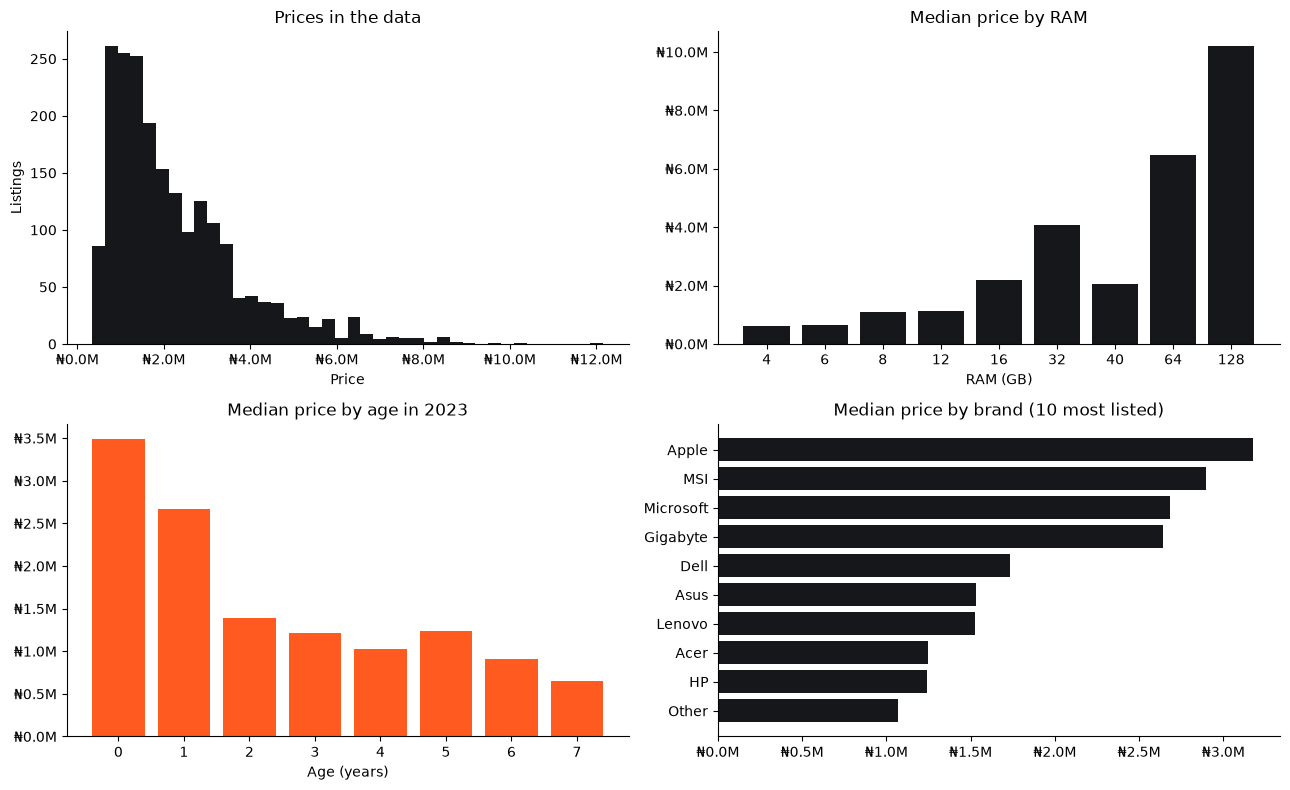

In [22]:
fig, axes = plt.subplots(2, 2, figsize=(13, 8))

ax = axes[0, 0]
ax.hist(df["price_ngn"], bins=40, color=INK)
ax.xaxis.set_major_formatter(millions)
ax.set(title="Prices in the data", xlabel="Price", ylabel="Listings")

ax = axes[0, 1]
by_ram = df.groupby(df["ram_gb"].astype(int))["price_ngn"].median()
ax.bar(by_ram.index.astype(str), by_ram, color=INK)
ax.yaxis.set_major_formatter(millions)
ax.set(title="Median price by RAM", xlabel="RAM (GB)")

ax = axes[1, 0]
by_age = df.groupby(df["age"].astype(int))["price_ngn"].median()
ax.bar(by_age.index.astype(str), by_age, color=ORANGE)
ax.yaxis.set_major_formatter(millions)
ax.set(title="Median price by age in 2023", xlabel="Age (years)")

ax = axes[1, 1]
top_brands = df["brand"].value_counts().head(10).index
by_brand = df[df["brand"].isin(top_brands)].groupby("brand")["price_ngn"].median().sort_values()
ax.barh(by_brand.index, by_brand, color=INK)
ax.xaxis.set_major_formatter(millions)
ax.set(title="Median price by brand (10 most listed)")

fig.tight_layout()
plt.show()

**What the charts show**
- **Prices are skewed right.** The middle half of laptops cost about ₦1.1M to ₦3.0M, with a long tail of gaming laptops and workstations above ₦4.4M. That's why the models predict the *logarithm* of the price (section 9).
- **More RAM, higher price,** step by step from 4 to 64 GB. The 40 and 128 GB bars are only 2 and 1 listings, so ignore them.
- **Age matters most early on.** The median falls from about ₦3.5M for the newest laptops to about ₦1.4M at two years old, then slowly to about ₦0.65M at seven. Only 144 of 2,061 laptops are older than three years, so the model knows least about old laptops, which are common in the used market.
- **Brand reflects product mix.** Apple, MSI, Microsoft and Gigabyte sell mostly premium or gaming machines, so their medians are high. HP and Acer sell many budget notebooks.

## 7. Features, target and leakage

- **Target:** `price_ngn`. Models learn its logarithm, because a feature like extra RAM tends to add a *percentage* to the price, not a fixed amount, and because prices are skewed.
- **Every feature is known when a seller lists the laptop.** Nothing is computed from the price.
- **The colour-variant trap.** 787 rows repeat another row's specs. A random split would put one colour in training and its twin in testing, and the test score would flatter the model. So the split is **grouped**: all variants of one laptop land on the same side.
- **`refurbished`** is in the training data but fixed to 1 when pricing, since every laptop in the app is second-hand.

## 8. Grouped train/test split *(why not a plain `train_test_split`?)*

15% of laptops are held back as the test set and only used once, at the end. Cross-validation inside the training set uses `GroupKFold`, with the same rule: one laptop's variants never straddle a split.

In [23]:
from sklearn.model_selection import GroupKFold

dev, test = tr.holdout_split(df)
y_dev, y_test = dev["price_ngn"].to_numpy(), test["price_ngn"].to_numpy()
groups = tr.spec_groups(dev)
cv = GroupKFold(5, shuffle=True, random_state=tr.SEED)
print(f"{len(dev)} laptops to train on, {len(test)} held back for testing")

1772 laptops to train on, 289 held back for testing


## 9. Preprocessing pipeline

- **`ColumnTransformer`:** text columns get a constant fill for blanks and one-hot encoding (`handle_unknown="ignore"`); numbers get median imputation and scaling. It sits inside a `Pipeline`, so it's learned from training folds only.
- **`TransformedTargetRegressor`:** trains on log(price) and turns predictions back into naira, so every error below is in naira.

In [24]:
from sklearn.compose import ColumnTransformer, TransformedTargetRegressor
from sklearn.dummy import DummyRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.metrics import mean_absolute_error, r2_score
from sklearn.model_selection import GridSearchCV, cross_val_predict
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.tree import DecisionTreeRegressor

CATEGORICAL = ["brand", "laptop_type", "cpu", "series"]
NUMERIC = ["cpu_tier", "ram_gb", "storage_gb", "storage_type", "gpu", "screen_inches", "age", "refurbished"]
X_dev, X_test = dev[CATEGORICAL + NUMERIC], test[CATEGORICAL + NUMERIC]


def in_log_space(model):
    preprocess = ColumnTransformer([
        ("text", make_pipeline(SimpleImputer(strategy="constant", fill_value="Unknown"), OneHotEncoder(handle_unknown="ignore")), CATEGORICAL),
        ("numbers", make_pipeline(SimpleImputer(strategy="median"), StandardScaler()), NUMERIC),
    ])
    return TransformedTargetRegressor(make_pipeline(preprocess, model), func=np.log, inverse_func=np.exp)

## 10. Compare models *(Weeks 4–5)*

Each model is tuned with `GridSearchCV` on the training set using grouped 5-fold cross-validation. **The winner is chosen by cross-validated error**, and only then do we look at the test set. A "median price" baseline shows what you'd get with no machine learning at all.

The project's model, LightGBM (gradient-boosted trees), was tuned separately with `model/tune.py`. Its settings are in `model/best_lgb.json`, and it adds three things the app needs:
- **Monotonic constraints:** more RAM or storage never lowers the price, and more years never raise it.
- **"Not sure" training:** copies of some rows have graphics, screen size or model name blanked, so the model learns what a blank answer is worth.
- **Five seeds averaged:** five models with different random seeds are averaged, which steadies predictions. Its cross-validation below uses one seed, to keep this notebook quick.

This cell takes a minute or two.

In [25]:
candidates = {
    "Median price (no ML)": (DummyRegressor(strategy="median"), None),
    "Linear regression": (in_log_space(LinearRegression()), None),
    "Ridge": (in_log_space(Ridge()), {"regressor__ridge__alpha": [0.1, 1, 10, 100]}),
    "Decision tree": (in_log_space(DecisionTreeRegressor(random_state=tr.SEED)),
                      {"regressor__decisiontreeregressor__max_depth": [4, 8, 12, None],
                       "regressor__decisiontreeregressor__min_samples_leaf": [1, 5, 10]}),
    "Random forest": (in_log_space(RandomForestRegressor(n_estimators=200, random_state=tr.SEED)),
                      {"regressor__randomforestregressor__max_features": [0.3, 0.6],
                       "regressor__randomforestregressor__min_samples_leaf": [1, 3]}),
}

rows = []
for name, (model, grid) in candidates.items():
    if grid:
        search = GridSearchCV(model, grid, scoring="neg_mean_absolute_error", cv=cv, n_jobs=-1).fit(X_dev, y_dev, groups=groups)
        best, cv_mae = search.best_estimator_, -search.best_score_
    else:
        best = model.fit(X_dev, y_dev)
        cv_mae = mean_absolute_error(y_dev, cross_val_predict(model, X_dev, y_dev, cv=cv, groups=groups))
    rows.append((name, cv_mae, best.predict(X_dev), best.predict(X_test)))

params, rounds, seeds = tr.tuned()
oof = np.zeros(len(dev))
for train_idx, valid_idx in cv.split(dev, groups=groups):
    oof[valid_idx] = tr.predict(tr.fit_seeds(dev.iloc[train_idx], params, rounds, 1), dev.iloc[valid_idx])
boosters = tr.fit_seeds(dev, params, rounds, seeds)
rows.append(("LightGBM (project)", mean_absolute_error(y_dev, oof), tr.predict(boosters, dev), tr.predict(boosters, test)))

results = pd.DataFrame([{
    "model": name,
    "CV error (₦)": round(cv_mae),
    "train error (₦)": round(mean_absolute_error(y_dev, train_pred)),
    "test error (₦)": round(mean_absolute_error(y_test, test_pred)),
    "test median error": f"{np.median(np.abs(y_test - test_pred) / y_test):.1%}",
    "test R²": round(r2_score(y_test, test_pred), 3),
} for name, cv_mae, train_pred, test_pred in rows]).sort_values("CV error (₦)").reset_index(drop=True)
predictions = {name: test_pred for name, _, _, test_pred in rows}
best_name = results.loc[0, "model"]
print("Chosen by cross-validation:", best_name)
results

Chosen by cross-validation: LightGBM (project)


,model,CV error (₦),train error (₦),test error (₦),test median error,test R²
0,LightGBM (project),373583,293803,422365,13.6%,0.818
1,Ridge,409944,383034,490847,15.8%,0.736
2,Linear regression,411395,382367,497395,16.4%,0.733
3,Random forest,414201,199700,427872,13.2%,0.814
4,Decision tree,515219,119677,541126,16.0%,0.748
5,Median price (no ML),1115086,1108477,1243926,46.0%,-0.141


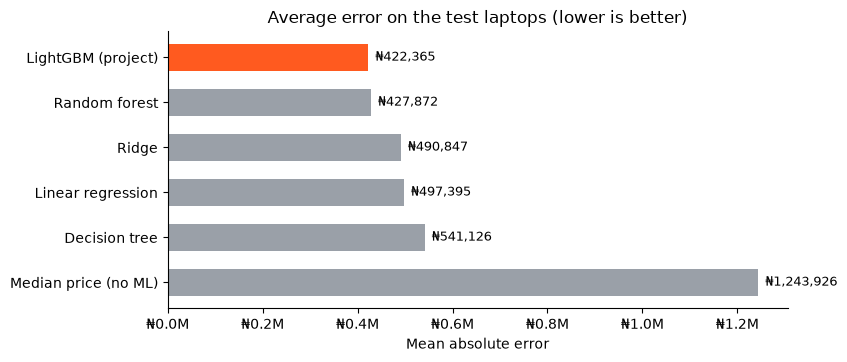

In [26]:
ordered = results.sort_values("test error (₦)", ascending=False)
fig, ax = plt.subplots(figsize=(8, 3.6))
ax.barh(ordered["model"], ordered["test error (₦)"], color=[ORANGE if m == best_name else GREY for m in ordered["model"]], height=0.6)
for y, value in enumerate(ordered["test error (₦)"]):
    ax.text(value + 15_000, y, naira(value), va="center", fontsize=9)
ax.xaxis.set_major_formatter(millions)
ax.set(title="Average error on the test laptops (lower is better)", xlabel="Mean absolute error")
plt.show()

**How to read the comparison**
- **Every model beats the no-ML baseline by a wide margin.** Guessing the median price is off by over ₦1.2M on average, and its R² below zero means it does worse than simply predicting the test set's own average.
- **LightGBM wins on cross-validation,** which is how the model was chosen. On the test set it also has the lowest average error (about ₦422,000) and the highest R² (0.82), with a 13.6% median error.
- **The single decision tree overfits.** Its training error is a fraction of its test error, because an unlimited-depth tree memorises the training laptops.
- **The random forest is a close second.** On the test set its median error is slightly lower (13.2%), but its average error is higher, its training error is far below its test error (overfitting), and it can't enforce "more RAM never lowers the price" the way the app needs.
- **Linear regression and ridge are a solid baseline.** Ridge's tuning barely helps here, because there are far more laptops than features.

### 10.1 Predicted against real price

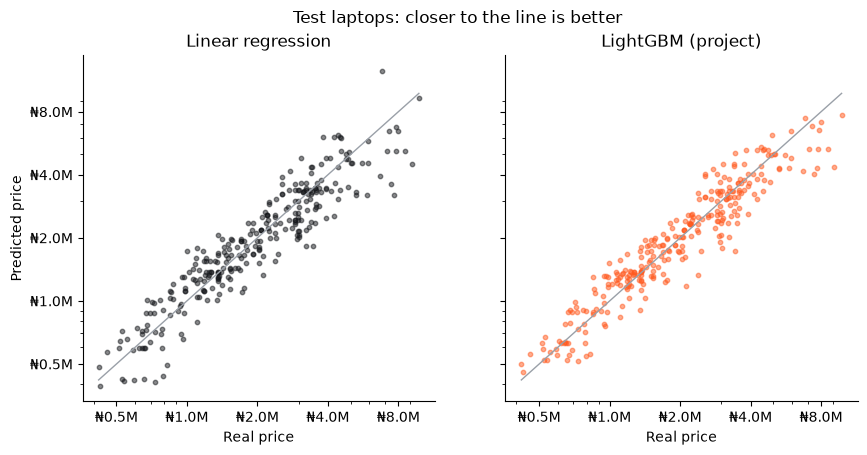

In [27]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4.5), sharex=True, sharey=True)
for ax, (name, colour) in zip(axes, [("Linear regression", INK), (best_name, ORANGE)]):
    ax.scatter(y_test, predictions[name], s=10, alpha=0.5, color=colour)
    ax.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], color=GREY, linewidth=1)
    ax.set(title=name, xscale="log", yscale="log", xlabel="Real price")
    ax.set_xticks(PRICE_TICKS)
    ax.set_yticks(PRICE_TICKS)
    ax.xaxis.set_major_formatter(millions)
    ax.yaxis.set_major_formatter(millions)
    ax.xaxis.set_minor_formatter(plt.NullFormatter())
    ax.yaxis.set_minor_formatter(plt.NullFormatter())
axes[0].set_ylabel("Predicted price")
fig.suptitle("Test laptops: closer to the line is better")
plt.show()

### 10.2 Residuals *(Week 3)*

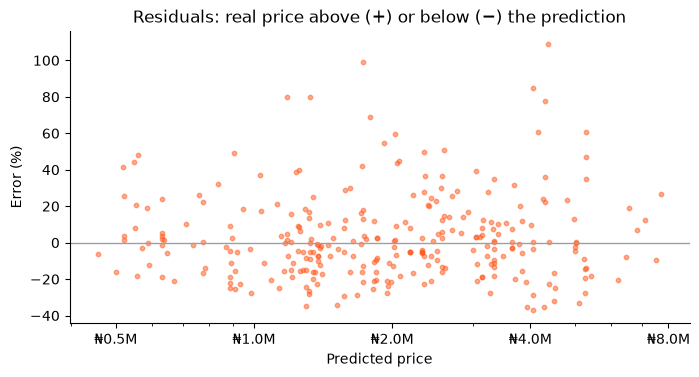

In [28]:
model_pred = predictions[best_name]
error_pct = (y_test - model_pred) / model_pred * 100
fig, ax = plt.subplots(figsize=(8, 3.8))
ax.scatter(model_pred, error_pct, s=10, alpha=0.5, color=ORANGE)
ax.axhline(0, color=GREY, linewidth=1)
ax.set(xscale="log", title="Residuals: real price above (+) or below (−) the prediction", xlabel="Predicted price", ylabel="Error (%)")
ax.set_xticks(PRICE_TICKS)
ax.xaxis.set_major_formatter(millions)
ax.xaxis.set_minor_formatter(plt.NullFormatter())
plt.show()

The errors scatter around zero at every price level, with no clear curve or funnel, so the model isn't systematically too high for cheap laptops or too low for expensive ones. Working in log space is what keeps the *percentage* error similar across prices.

### 10.3 What drives the price?

The app explains every price with SHAP values: how far each feature pushed one laptop's price from the average. Averaging their size across the test laptops shows which features matter most overall.

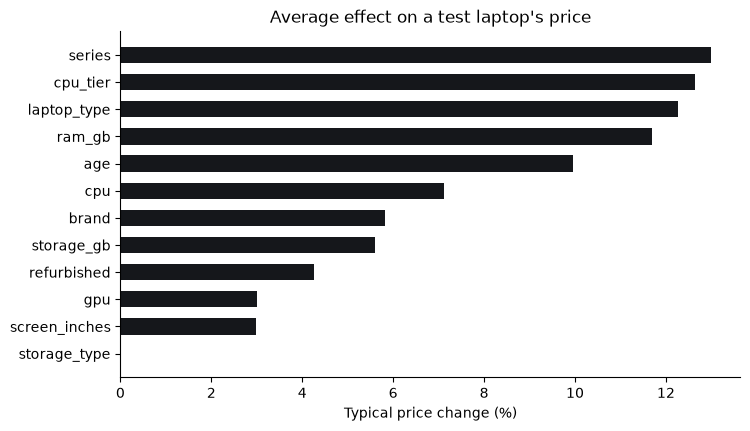

In [29]:
shap_values = np.mean([b.predict(tr.encode(test), pred_contrib=True) for b in boosters], axis=0)[:, :-1]
importance = pd.Series(np.abs(shap_values).mean(axis=0), index=tr.FEATURES)
importance = (np.exp(importance) - 1).mul(100).sort_values()
fig, ax = plt.subplots(figsize=(8, 4.5))
ax.barh(importance.index, importance, color=INK, height=0.6)
ax.set(title="Average effect on a test laptop's price", xlabel="Typical price change (%)")
plt.show()

- **Product line, CPU tier, laptop type, RAM and age** move prices the most, each by about 10 to 13% on a typical laptop.
- **Storage type barely registers,** because the data has no hard drives to compare against. That's a data gap, not proof that hard drives don't matter.
- **Graphics and screen size** matter less once the product line and laptop type are known, which is good news, since many sellers won't know them.

## 11. Train the final model and save it *(Week 4)*

The final model trains on every laptop, including the test set, since its score is already measured. `train.py` saves five LightGBM model files plus `meta.json`, which holds the category lists, the fair range and the scores. The app loads these files. This takes about a minute.

In [30]:
with contextlib.redirect_stdout(io.StringIO()):
    tr.main()

for path in sorted(tr.ARTIFACTS.glob("*.*")):
    print(f"{path.name:<12} {path.stat().st_size / 1e6:5.2f} MB")

.gitkeep      0.00 MB
meta.json     0.00 MB
model_0.txt   2.16 MB
model_1.txt   2.26 MB
model_2.txt   2.23 MB
model_3.txt   2.28 MB
model_4.txt   2.24 MB


In [31]:
from app.predictors.model import ModelPredictor
from app.schemas import LaptopSpecs

started = time.perf_counter()
predictor = ModelPredictor()
print(f"Reloaded {len(predictor.boosters)} models in {time.perf_counter() - started:.2f} s")

Reloaded 5 models in 0.14 s


## 12. The fair range

The receipt shows a range as well as an estimate. `train.py` measures how far real prices land from cross-validated predictions, and keeps the 10th to 90th percentile of the ratio. On the test laptops, the real price should fall inside about 80% of the time.

In [32]:
meta = json.loads((tr.ARTIFACTS / "meta.json").read_text())
low, high = meta["range_ratio"]
inside = (y_test >= model_pred * low) & (y_test <= model_pred * high)
print(f"Fair range: {low:.2f}× to {high:.2f}× the estimate")
print(f"Test laptops whose real price falls inside it: {inside.mean():.0%}")

Fair range: 0.78× to 1.32× the estimate
Test laptops whose real price falls inside it: 80%


## 13. From prediction to receipt

This prices the example laptop from `contract/example-request.json` exactly as the app does. Each line comes from the model's SHAP values, converted from log space to naira so the receipt adds up to the naira. Condition and battery aren't in the data, so they're fixed adjustments applied afterwards (orange).

In [33]:
example = json.loads((ROOT / "contract" / "example-request.json").read_text())
started = time.perf_counter()
slip = predictor.appraise(LaptopSpecs(**example))
elapsed_ms = (time.perf_counter() - started) * 1000

print(f"{example['brand']} {example['model_name']}, {example['year']} (priced in {elapsed_ms:.0f} ms)")
print("Starting point (average used laptop):", naira(slip.base_value))
lines = pd.DataFrame([line.model_dump() for line in slip.contributions])[["label", "amount", "source"]]
display(lines.assign(amount=lines["amount"].map(lambda a: f"{a:+,}")))
print("Estimate:", naira(slip.estimate), f"(fair range {naira(slip.range.low)} to {naira(slip.range.high)})")
print("Adds up:", slip.base_value + lines["amount"].sum() == slip.estimate)

Dell XPS 13, 2021 (priced in 37 ms)
Starting point (average used laptop): ₦1,631,000


,label,amount,source
0,Dell brand,"+320,000",model
1,Ultrabook build,"+128,000",model
2,Intel Core i7,"+249,000",model
3,XPS 13 model,"+149,000",model
4,16 GB RAM,"+64,000",model
5,512 GB storage,"-82,000",model
6,Graphics not known,"-6,000",model
7,Screen size not known,"-1,000",model
8,"Age, 5 years","-523,000",model
9,Good condition,"-96,000",adjustment


Estimate: ₦1,778,000 (fair range ₦1,385,000 to ₦2,340,000)
Adds up: True


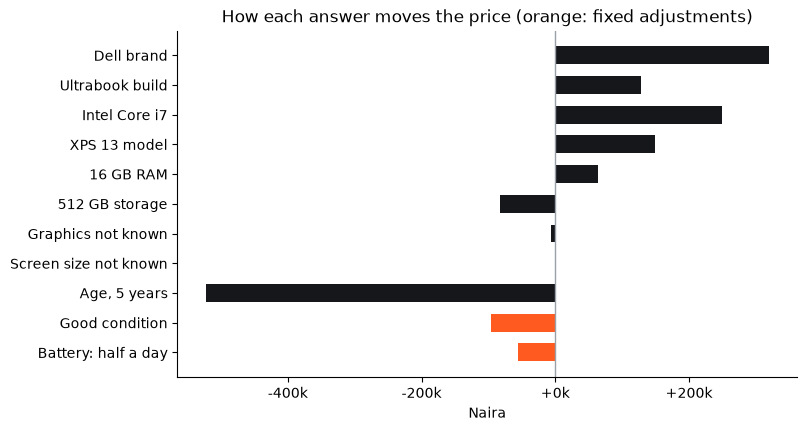

In [34]:
ordered = lines.iloc[::-1]
fig, ax = plt.subplots(figsize=(8, 4.5))
ax.barh(ordered["label"], ordered["amount"], color=[ORANGE if s == "adjustment" else INK for s in ordered["source"]], height=0.6)
ax.axvline(0, color=GREY, linewidth=1)
ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda value, _: f"{value / 1e3:+,.0f}k"))
ax.set(title="How each answer moves the price (orange: fixed adjustments)", xlabel="Naira")
plt.show()

## 14. How the app uses this

The model sits behind a small API. The web app sends the seller's answers to `POST /api/appraise`, and gets back the estimate, the fair range and the receipt lines above. The contract between them is in `docs/CONTRACT.md`, and the API's tests check that every receipt adds up exactly, that newer laptops and more RAM never lower the price, and that each answer gets one line.

## 15. Limitations, responsible use and next steps

**Limitations**
1. **European shop prices.** The data is a Spanish shop's new and refurbished stock in 2023, converted at €1 = ₦1,700. Estimates run well above the Nigerian used market.
2. **Few old laptops.** Only 144 of 2,061 laptops are older than three years. Ages past seven years continue the depreciation the model learned, and are marked "estimated" on the receipt.
3. **Condition and battery aren't learned.** The data has no such columns, so they're fixed adjustments based on judgement, not evidence.
4. **Newest chips.** Apple M3 and M4 aren't in the data, so they're priced like an M2 of the same age and marked "estimated".
5. **The exchange rate is fixed** in `train.py` and needs updating as the naira moves.

**Responsible use**
- The estimate is a **reference, not a valuation,** which is why the receipt shows a range rather than one exact figure.
- Every price comes with its reasons, so a buyer or seller can see *why* and challenge a line that looks wrong.

**Next steps**
1. Collect Nigerian used listings, for example 100 to 200 from online marketplaces, to calibrate the price level or retrain.
2. Record condition and battery alongside those prices, so the adjustments can be learned instead of fixed.
3. Re-check accuracy on Nigerian listings before trusting the range in the local market.

## 16. Defence preparation: likely questions

- **Why predict log(price) instead of price?** Prices are skewed, and specs tend to change a price by a percentage, so errors stay comparable between a ₦300k laptop and a ₦5M one.
- **Why not a random train/test split?** 787 listings are colour variants of another listing. A random split would test the model on near-copies of training laptops and flatter the score. Grouping by specs prevents that.
- **Why LightGBM over the random forest, when their test errors are close?** It wins on cross-validation, which is how we chose, before looking at the test set. On the test set the two trade places: LightGBM has the lower average error, the forest a slightly lower median error. It also supports monotonic constraints and gives exact SHAP explanations quickly, about 20 ms per laptop, which the live receipt needs.
- **What are monotonic constraints?** Rules built into the trees: more RAM or storage, or a better CPU tier, can never lower the price, and more years can never raise it. They stop the model learning nonsense from noisy data.
- **How does the model handle "not sure" answers?** Training includes copies of laptops with graphics, screen size or model name blanked, so a blank answer gets a sensible price instead of an error.
- **Where do the receipt lines come from?** SHAP values from the trees, one per feature, converted from log space to naira and rounded so the receipt adds up exactly.
- **What does the fair range mean?** For 80% of laptops the model has never seen, the real price falls inside it. It's measured with cross-validation on the training set and confirmed on the test set.
- **Why are condition and battery fixed adjustments?** The data has no condition or battery columns, so there's nothing to learn from. The receipt marks those lines as adjustments.
- **Why are the prices high for Nigeria?** The data comes from a European shop. The model learns how specs *relate* to price well, but the overall price level needs local data to calibrate (section 15).